# 1. Données et exploration

On construit une table avec une ligne par athlète et par jour (152 jours, du 1er novembre 2019 au 31 mars 2020), puis on regarde ce qu'elle contient. Le code de lecture est dans `src/data.py`.

In [1]:
import os, sys, subprocess
from pathlib import Path

if "google.colab" in sys.modules:   # Colab : code depuis GitHub, données depuis Google Drive
    from google.colab import drive
    drive.mount("/content/drive")
    os.environ["DATA_DIR"] = "/content/drive/MyDrive/Colab Notebooks/athlete-data/data/raw"
    repo = Path("/content/athlete-monitoring")
    if repo.exists():
        for generated in ("notebooks", "data/processed"):   # fichiers régénérés, à remettre avant la mise à jour
            subprocess.run(["git", "-C", str(repo), "checkout", "--", generated], capture_output=True)
        subprocess.run(["git", "-C", str(repo), "pull", "-q"], check=True)
    else:
        subprocess.run(["git", "clone", "-q", "https://github.com/Harena21/athlete-monitoring.git", str(repo)],
                       check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(repo / "requirements.txt")], check=True)
else:
    repo = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(repo)
sys.path.insert(0, str(repo))

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
COLORS = {"p01": "#2a78d6", "p03": "#eb6834", "p05": "#1baf7a"}

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
from src.data import build_daily
daily = build_daily()
print(daily.shape)
daily.head()

(456, 33)


,date,steps,calories,distance_km,hr_mean,hr_wear_minutes,resting_hr,zone1_min,zone2_min,zone3_min,...,weight,alcohol,participant,age,trimp,load_7d,load_28d,acwr,monotony,resting_hr_delta
0,2019-11-01,17873.0,4009.10,14.42400,66.140075,1421.0,53.741074,164.0,3.0,0.0,...,NaN,NaN,p01,48,256.5,NaN,NaN,NaN,NaN,NaN
1,2019-11-02,13118.0,3533.56,10.58480,62.602226,1393.0,52.881497,137.0,0.0,0.0,...,NaN,NaN,p01,48,205.5,NaN,NaN,NaN,NaN,NaN
2,2019-11-03,14312.0,3748.73,11.46085,64.551841,1368.0,53.222024,141.0,0.0,0.0,...,NaN,NaN,p01,48,211.5,NaN,NaN,NaN,NaN,NaN
3,2019-11-04,10970.0,3353.38,8.85970,63.552109,1414.0,54.311141,100.0,0.0,0.0,...,NaN,NaN,p01,48,150.0,205.875,NaN,NaN,4.716198,NaN
4,2019-11-05,16186.0,3794.63,13.71470,66.672530,1412.0,52.259110,94.0,7.0,12.0,...,NaN,NaN,p01,48,225.5,209.800,NaN,NaN,5.405852,NaN


## Quelles sources sont remplies ?

Nombre de jours (sur 152) avec au moins une valeur, par source.

In [3]:
sources = {"pas (Fitbit)": "steps", "FC détaillée": "hr_mean", "FC de repos": "resting_hr", "sommeil": "sleep_minutes",
           "questionnaire bien-être": "well_readiness", "sRPE": "srpe_load", "questionnaire blessure": "injury",
           "rapport repas": "n_meals"}
pd.DataFrame({k: daily.groupby("participant")[v].count() for k, v in sources.items()}).T

participant,p01,p03,p05
pas (Fitbit),152,122,144
FC détaillée,152,0,145
FC de repos,152,101,86
sommeil,150,78,118
questionnaire bien-être,138,75,134
sRPE,31,2,8
questionnaire blessure,24,11,10
rapport repas,100,113,117


Ce qui ressort :
- la sRPE n'est remplie que 31, 2 et 8 jours. Je calcule donc la charge à partir des minutes passées dans les zones de fréquence cardiaque (TRIMP), disponibles presque tous les jours ;
- p03 n'a pas de fichier de fréquence cardiaque détaillée ;
- le questionnaire de blessure est rarement rempli. Je considère qu'une absence de rapport veut dire une absence de blessure, faute de mieux.

Deux détails réglés pendant la lecture : pmsys et le score de sommeil sont en UTC alors que Fitbit est en heure locale (tout est ramené à l'heure d'Oslo), et la colonne `timestamp` de `reporting.csv` mélange jour et mois, donc j'utilise la colonne `date`.

## Blessures signalées

In [4]:
daily.loc[daily["injury"] == 1, ["participant", "date"]]

,participant,date
67,p01,2020-01-07
304,p05,2019-11-01
310,p05,2019-11-07
394,p05,2020-01-30
395,p05,2020-01-31
403,p05,2020-02-08
409,p05,2020-02-14
424,p05,2020-02-29
431,p05,2020-03-07
439,p05,2020-03-15


p01 a une blessure, p03 aucune, p05 dix rapports, dont la plupart pendant le même épisode au pied (fin janvier à mi-mars). Il y a très peu d'épisodes distincts, le modèle de blessure sera donc exploratoire.

## Réponses au questionnaire

Les échelles vont de 1 à 5 (readiness de 0 à 10), mais certaines réponses valent 0.

In [5]:
for col in ["well_fatigue", "well_readiness"]:
    print(daily.groupby("participant")[col].value_counts().unstack(fill_value=0), "\n")

well_fatigue  0.0  1.0  2.0  3.0  4.0
participant                          
p01             0    2   57   78    1
p03             0    0    6   68    1
p05             2    9   21  101    1 

well_readiness  0.0  2.0  3.0  4.0  5.0  6.0  7.0  8.0
participant                                           
p01               0    1    6   12   18   31   45   25
p03               0    0    1    2   71    1    0    0
p05              57    0    1    5   70    0    0    1 



Les 0 sont des codes invalides : sur les échelles de 1 à 5 ils n'apparaissent que sur des lignes entièrement à 0, et la readiness de p05 reste à 0 pendant deux mois alors que ses autres réponses varient (curseur jamais déplacé). p03 répond presque toujours 3 : ses réponses apportent peu d'information.

## Valeurs manquantes par athlète

In [6]:
cols = ["steps", "hr_mean", "resting_hr", "sleep_score", "well_readiness", "srpe_load", "weight"]
daily[cols].isna().groupby(daily["participant"]).mean().round(2)

,steps,hr_mean,resting_hr,sleep_score,well_readiness,srpe_load,weight
participant,,,,,,,
p01,0.00,0.00,0.00,0.01,0.09,0.80,0.51
p03,0.20,1.00,0.34,0.52,0.51,0.99,0.41
p05,0.05,0.05,0.43,0.23,0.12,0.95,0.36


Les manques ne sont pas répartis au hasard (jours sans montre, questionnaires non remplis, FC absente pour p03). Il faudra traiter chaque athlète séparément.

## Distributions

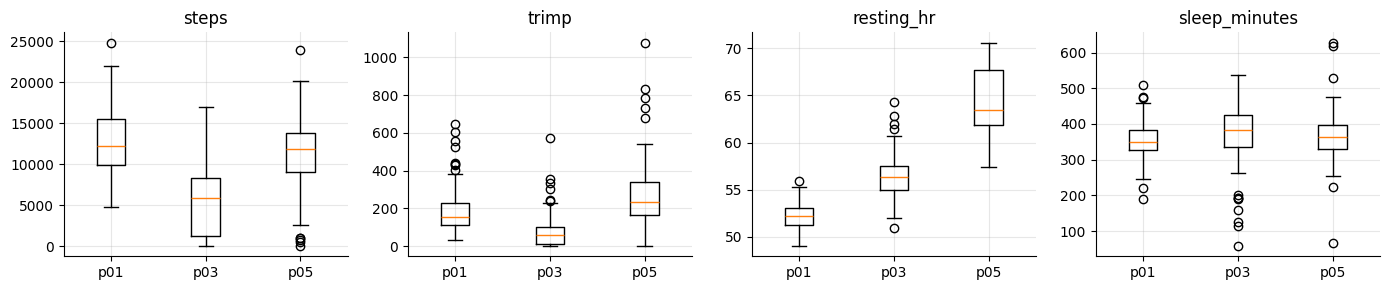

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, col in zip(axes, ["steps", "trimp", "resting_hr", "sleep_minutes"]):
    ax.boxplot([daily.loc[daily.participant == p, col].dropna() for p in COLORS], tick_labels=list(COLORS))
    ax.set_title(col)
plt.tight_layout()

Les niveaux sont très différents d'un athlète à l'autre (FC de repos, nombre de pas) : il vaut mieux comparer chaque athlète à lui-même.

## Charge d'entraînement et readiness dans le temps (traits rouges = blessures)

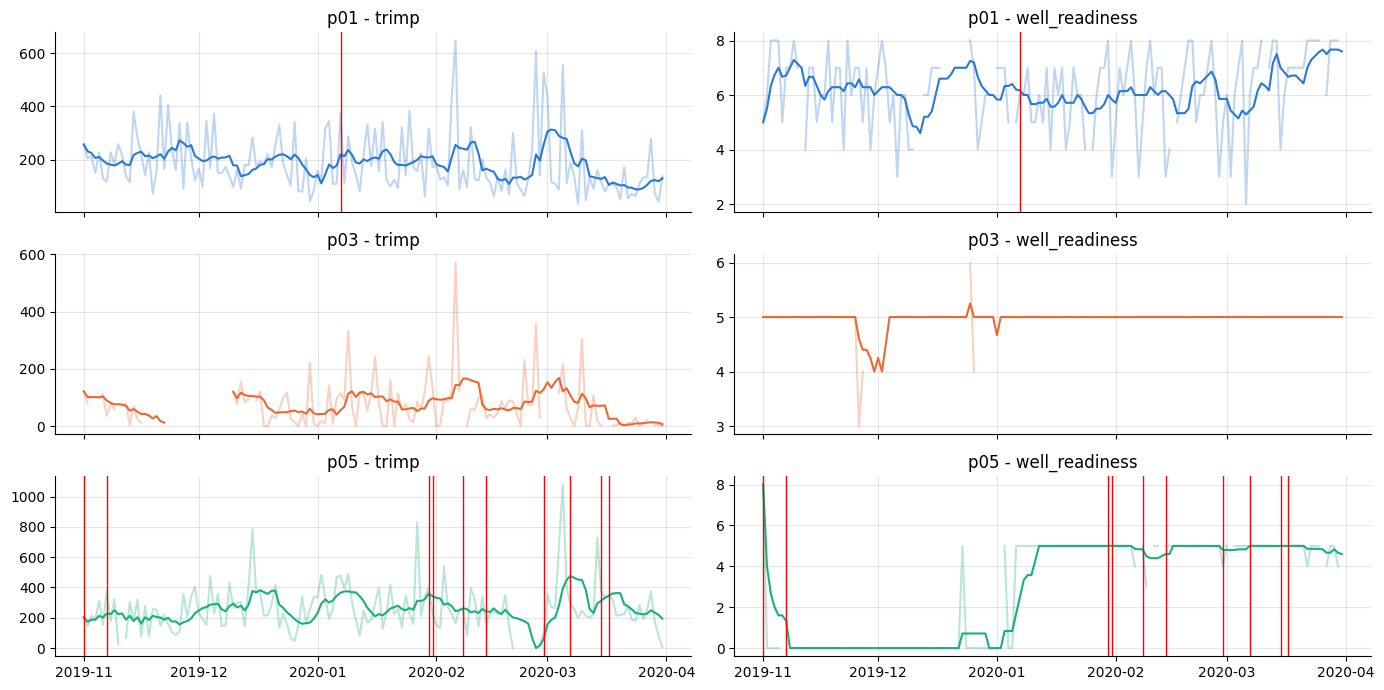

In [8]:
fig, axes = plt.subplots(3, 2, figsize=(14, 7), sharex=True)
for i, p in enumerate(COLORS):
    sub = daily[daily.participant == p]
    for j, col in enumerate(["trimp", "well_readiness"]):
        ax = axes[i, j]
        ax.plot(sub["date"], sub[col], color=COLORS[p], alpha=0.3)
        ax.plot(sub["date"], sub[col].rolling(7, min_periods=1).mean(), color=COLORS[p])
        for d in sub.loc[sub["injury"] == 1, "date"]:
            ax.axvline(d, color="red", lw=1)
        ax.set_title(f"{p} - {col}")
plt.tight_layout()

## La montre dit-elle quelque chose du ressenti ?

In [9]:
cols = ["well_readiness", "well_fatigue", "sleep_score", "sleep_minutes", "resting_hr", "trimp", "acwr"]
z = daily[cols].groupby(daily["participant"]).transform(lambda s: (s - s.mean()) / s.std())
z.corr("spearman")[["well_readiness", "well_fatigue"]].round(2)

,well_readiness,well_fatigue
well_readiness,1.00,0.51
well_fatigue,0.51,1.00
sleep_score,0.20,0.14
sleep_minutes,0.03,0.11
resting_hr,-0.18,-0.07
trimp,0.13,0.09
acwr,-0.14,-0.09


Les corrélations sont calculées à l'intérieur de chaque athlète (valeurs centrées-réduites par athlète). Elles sont faibles : la montre dit peu de choses du ressenti déclaré, ce qui rejoint Saw et al. (2016). Cela rendra la prédiction de la forme difficile.